# 01 — Dataset Understanding (FD001)

**Project:** Predictive Intelligence · **Phase 2, Milestone 2**

## Objective

Before predicting anything, we need to know exactly what we have been given. This notebook answers five questions about the FD001 subset of NASA C-MAPSS:

1. What is in the three files, and how are they shaped?
2. Is the data complete and clean?
3. How long do engines live?
4. Which measurements actually change, and which never move?
5. How do we turn "the engine failed at cycle 192" into a training label?

No model is trained here.

> **Data note.** C-MAPSS is *simulated* turbofan data from NASA. It is a research benchmark, not telemetry from a real aircraft.

## 1. Setup

The loading code lives in `src/data/cmapss.py` so that every notebook reads the files the same way. The plotting defaults live in `src/visualization/theme.py`.

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

# Make the project's own code importable, wherever the notebook is launched from.
project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
sys.path.insert(0, str(project_root))

from src.data.cmapss import (
    SENSOR_COLUMNS,
    SENSOR_INFO,
    SETTING_COLUMNS,
    add_training_rul,
    load_subset,
)
from src.visualization import theme

theme.apply_theme()
# Store interactive charts so they display in VS Code, JupyterLab and exported HTML.
pio.renderers.default = "plotly_mimetype+notebook_connected"
pd.set_option("display.max_columns", 30)

## 2. Loading the three files

FD001 comes as three text files:

| File | What it is | Maintenance analogy |
|---|---|---|
| `train_FD001.txt` | Engines recorded from first flight **until failure** | Complete service records of retired engines |
| `test_FD001.txt` | Engines recorded up to some point **before** failure | Records of engines still in service |
| `RUL_FD001.txt` | How many cycles each test engine really had left | What later happened to those engines |

The files have no header row, so we attach the column names ourselves. One row is one engine during one **cycle** (think: one flight).

In [ ]:
train, test, test_rul = load_subset("FD001")

for name, table in [("train", train), ("test", test), ("test_rul", test_rul)]:
    print(f"{name:9s} {table.shape[0]:>6,} rows x {table.shape[1]} columns")

train     20,631 rows x 26 columns
test      13,096 rows x 26 columns
test_rul     100 rows x 2 columns


In [ ]:
train.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


**Reading the table.** Each row has:

- `engine_id` and `cycle` — which engine, and how many flights it has completed.
- `setting_1` to `setting_3` — the conditions the engine was flown in (by convention: altitude, Mach number, throttle angle).
- `sensor_1` to `sensor_21` — temperatures, pressures, speeds and flows inside the engine.

The dataset README only numbers the sensors. The names below come from Table 2 of the NASA paper, matched in order. That mapping is the convention in the literature, but it is an inference, not something the files state.

In [ ]:
sensor_reference = pd.DataFrame(SENSOR_INFO, index=["symbol", "description", "unit"]).T
sensor_reference

,symbol,description,unit
sensor_1,T2,Total temperature at fan inlet,°R
sensor_2,T24,Total temperature at LPC outlet,°R
sensor_3,T30,Total temperature at HPC outlet,°R
sensor_4,T50,Total temperature at LPT outlet,°R
sensor_5,P2,Pressure at fan inlet,psia
sensor_6,P15,Total pressure in bypass duct,psia
sensor_7,P30,Total pressure at HPC outlet,psia
sensor_8,Nf,Physical fan speed,rpm
sensor_9,Nc,Physical core speed,rpm
sensor_10,epr,Engine pressure ratio (P50/P2),-


## 3. Is the data complete?

Three basic checks before trusting anything else:

- **Missing values** — a gap in a sensor log would need handling before modelling.
- **Duplicate rows** — the same reading recorded twice would count twice.
- **Cycle continuity** — each engine's cycles should run 1, 2, 3, … with no gaps; a time-series model assumes evenly spaced steps.

In [ ]:
def check_table(table: pd.DataFrame) -> dict:
    cycle_steps = table.groupby("engine_id")["cycle"].diff().dropna()
    first_cycles = table.groupby("engine_id")["cycle"].min()
    return {
        "missing values": int(table.isna().sum().sum()),
        "duplicate rows": int(table.duplicated().sum()),
        "engines": table["engine_id"].nunique(),
        "every engine starts at cycle 1": bool((first_cycles == 1).all()),
        "cycles always increase by 1": bool((cycle_steps == 1).all()),
    }

pd.DataFrame({"train": check_table(train), "test": check_table(test)})

,train,test
missing values,0,0
duplicate rows,0,0
engines,100,100
every engine starts at cycle 1,True,True
cycles always increase by 1,True,True


**Finding.** Both tables are complete: no missing values, no duplicates, 100 engines each, and unbroken cycle counts. No cleaning is needed. That is unusually tidy and is a reminder that this is simulated data; real maintenance records are rarely this clean.

## 4. How long do engines live?

For a training engine, the last recorded cycle is the cycle at which it failed, so the maximum cycle is its total life. For a test engine, the last recorded cycle is only where the recording *stops*.

In [ ]:
train_life = train.groupby("engine_id")["cycle"].max().rename("cycles_to_failure")
test_history = test.groupby("engine_id")["cycle"].max().rename("cycles_recorded")

pd.DataFrame({
    "train: cycles to failure": train_life.describe(),
    "test: cycles recorded": test_history.describe(),
    "test: true RUL at last cycle": test_rul["true_rul"].describe(),
}).round(1)

,train: cycles to failure,test: cycles recorded,test: true RUL at last cycle
count,100.0,100.0,100.0
mean,206.3,131.0,75.5
std,46.3,53.6,41.8
min,128.0,31.0,7.0
25%,177.0,88.8,32.8
50%,199.0,133.5,86.0
75%,229.2,164.2,112.2
max,362.0,303.0,145.0


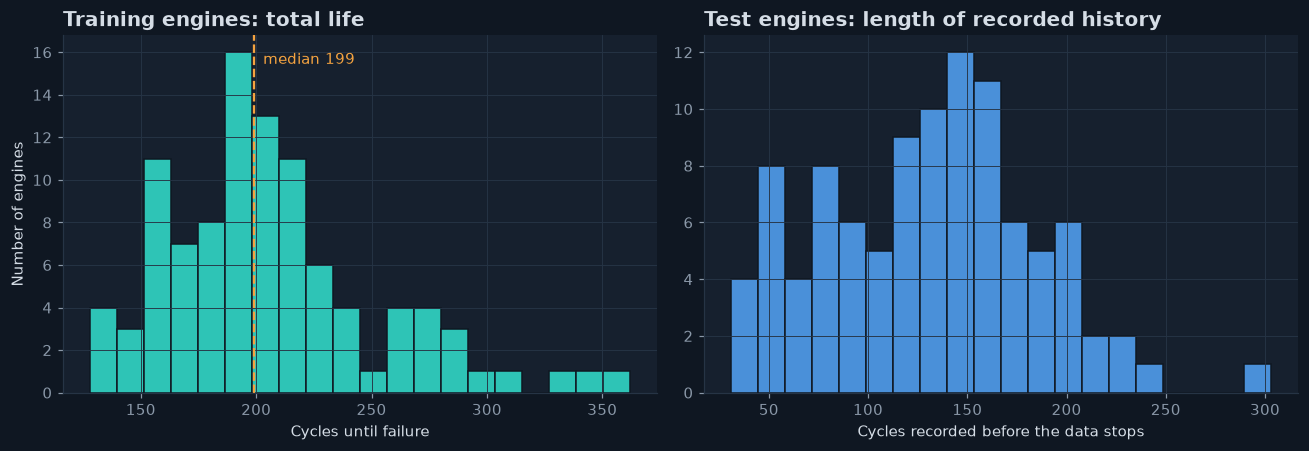

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].hist(train_life, bins=20, color=theme.TEAL, edgecolor=theme.BACKGROUND)
axes[0].axvline(train_life.median(), color=theme.AMBER, linestyle="--", linewidth=1.5)
axes[0].text(train_life.median() + 4, axes[0].get_ylim()[1] * 0.92,
             f"median {train_life.median():.0f}", color=theme.AMBER)
axes[0].set_title("Training engines: total life")
axes[0].set_xlabel("Cycles until failure")
axes[0].set_ylabel("Number of engines")

axes[1].hist(test_history, bins=20, color=theme.BLUE, edgecolor=theme.BACKGROUND)
axes[1].set_title("Test engines: length of recorded history")
axes[1].set_xlabel("Cycles recorded before the data stops")

fig.tight_layout()
plt.show()

**Findings.**

- Training engines last between 128 and 362 cycles, with a median of 199. The longest-lived engine survives almost three times as long as the shortest. Engines of the same type do not wear out at the same rate, which is exactly why a fixed "replace after N flights" rule wastes life on some engines and is too late for others.
- The distribution has a long right tail: most engines fail around 180–230 cycles, a few last much longer.
- Test histories are shorter (median about 134 cycles) because they are cut off before failure. Some test engines have only 31 cycles of history. Any windowing scheme we design in Phase 4 has to cope with histories that short.

### A sanity check on the test labels

If we add each test engine's recorded cycles to its true remaining life, we get its total life. Those totals should look like the training lifetimes, because both sets come from the same simulated fleet. If they did not, a model trained on one would not transfer to the other.

In [ ]:
test_total_life = test_history.to_numpy() + test_rul["true_rul"].to_numpy()

pd.DataFrame({
    "train total life": train_life.describe(),
    "test total life (recorded + true RUL)": pd.Series(test_total_life).describe(),
}).round(1)

,train total life,test total life (recorded + true RUL)
count,100.0,100.0
mean,206.3,206.5
std,46.3,44.0
min,128.0,141.0
25%,177.0,174.8
50%,199.0,199.0
75%,229.2,227.8
max,362.0,341.0


**Finding.** The two columns are very close (means of roughly 206 cycles in both). The test engines are the same kind of engine as the training ones; they have simply been observed for a shorter time. Note that we used the test labels here only to check the data's consistency, not to make any modelling choice.

## 5. Operating settings

The three settings describe the flight condition. A sensor reading depends on both the engine's health and the condition it is flown in, so we need to know how much the conditions vary.

In [ ]:
train[SETTING_COLUMNS].describe().loc[['min', 'max', 'mean', 'std']].round(5)

,setting_1,setting_2,setting_3
min,-0.00870,-0.00060,100.0
max,0.00870,0.00060,100.0
mean,-0.00001,0.00000,100.0
std,0.00219,0.00029,0.0


**Finding.** `setting_3` is exactly 100 for every row, and the other two barely move around zero. FD001 is flown in a single condition (sea level). This is what makes FD001 the right starting point: when a sensor drifts, it is because the engine is changing, not because the flight condition changed. In FD002 and FD004 there are six conditions and this will no longer hold.

## 6. Which sensors carry information?

A sensor that shows the same value on every flight of every engine cannot tell a healthy engine from a worn one. Think of a gauge whose needle is stuck: it is not wrong, but it is not useful.

We count the number of distinct values each sensor takes. Counting distinct values is more reliable than checking for zero standard deviation, because floating-point rounding can make the standard deviation of a constant column come out as a tiny non-zero number.

In [ ]:
sensor_summary = train[SENSOR_COLUMNS].agg(["nunique", "min", "max", "mean", "std"]).T
sensor_summary.insert(0, "symbol", [SENSOR_INFO[name][0] for name in sensor_summary.index])
sensor_summary["nunique"] = sensor_summary["nunique"].astype(int)

constant_sensors = sensor_summary.index[sensor_summary["nunique"] == 1].tolist()
two_value_sensors = sensor_summary.index[sensor_summary["nunique"] == 2].tolist()

print("Constant in train:", constant_sensors)
print("Only two distinct values:", two_value_sensors)
print("Same constant sensors in test:",
      constant_sensors == [c for c in SENSOR_COLUMNS if test[c].nunique() == 1])

sensor_summary.round(4)

Constant in train: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Only two distinct values: ['sensor_6']
Same constant sensors in test: True


,symbol,nunique,min,max,mean,std
sensor_1,T2,1,518.6700,518.6700,518.6700,0.0000
sensor_2,T24,310,641.2100,644.5300,642.6809,0.5001
sensor_3,T30,3012,1571.0400,1616.9100,1590.5231,6.1311
sensor_4,T50,4051,1382.2500,1441.4900,1408.9338,9.0006
sensor_5,P2,1,14.6200,14.6200,14.6200,0.0000
sensor_6,P15,2,21.6000,21.6100,21.6098,0.0014
sensor_7,P30,513,549.8500,556.0600,553.3677,0.8851
sensor_8,Nf,53,2387.9000,2388.5600,2388.0967,0.0710
sensor_9,Nc,6403,9021.7300,9244.5900,9065.2429,22.0829
sensor_10,epr,1,1.3000,1.3000,1.3000,0.0000


**Findings.**

- **Six sensors never change:** 1 (T2), 5 (P2), 10 (epr), 16 (farB), 18 (Nf_dmd) and 19 (PCNfR_dmd). This makes physical sense for the first two and the last two: fan-inlet temperature and pressure are fixed by flying at sea level, and the *demanded* fan speeds are set-points, not responses.
- **Sensor 6 (P15)** takes only two values, 21.60 and 21.61. That is one step of rounding, so it is effectively constant too.
- The remaining 14 sensors vary and are candidates for modelling.

Together with `setting_3`, that is 7 exactly-constant columns out of 24. We do **not** drop anything yet. Removing columns is a modelling decision and will be made, tested and logged in Phase 4. It is also specific to FD001: in the multi-condition subsets these same sensors do vary.

## 7. Building the training label: Remaining Useful Life

**Remaining Useful Life (RUL)** is the number of cycles an engine has left before it fails.

The training file has no RUL column, but we can compute it. Because each training engine is recorded until it fails, its last cycle is the failure point:

$$\text{RUL} = \text{last cycle of that engine} - \text{current cycle}$$

Example: an engine that fails at cycle 192 has RUL 191 at cycle 1, RUL 100 at cycle 92, and RUL 0 at its final cycle.

This works **only for training engines**. A test engine's last row is not its failure, so applying the same formula there would give wrong labels. For test engines the label comes from the RUL file.

In [ ]:
train_labelled = add_training_rul(train)

example_engine = 1
example = train_labelled.loc[train_labelled["engine_id"] == example_engine, ["engine_id", "cycle", "rul"]]
pd.concat([example.head(3), example.tail(3)])

,engine_id,cycle,rul
0,1,1,191
1,1,2,190
2,1,3,189
189,1,190,2
190,1,191,1
191,1,192,0


In [ ]:
final_rows = train_labelled.groupby("engine_id")["rul"].min()
print("Every training engine ends at RUL 0:", bool((final_rows == 0).all()))
print(f"RUL range in training data: {train_labelled['rul'].min()} to {train_labelled['rul'].max()}")

Every training engine ends at RUL 0: True
RUL range in training data: 0 to 361


### What the test labels look like

For the test set we have one true RUL per engine, valid at that engine's last recorded cycle.

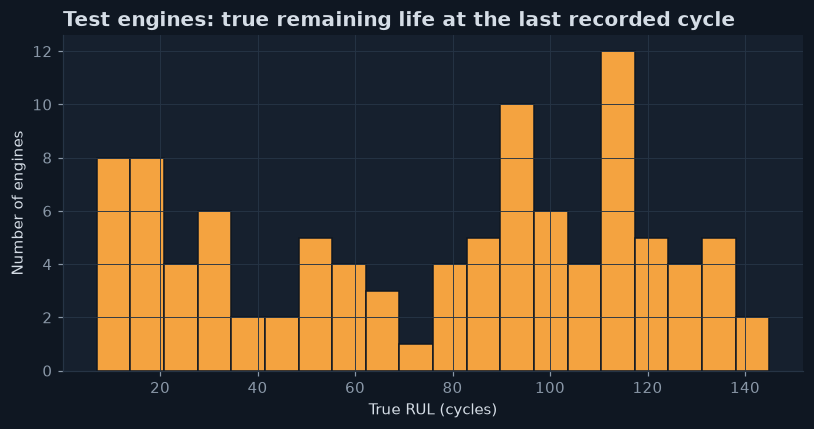

,engine_id,last_recorded_cycle,true_rul
0,1,31,112
1,2,49,98
2,3,126,69
3,4,106,82
4,5,98,91


In [ ]:
test_last_cycle = test.groupby("engine_id").tail(1)[["engine_id", "cycle"]].merge(test_rul, on="engine_id")
test_last_cycle = test_last_cycle.rename(columns={"cycle": "last_recorded_cycle"})

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(test_last_cycle["true_rul"], bins=20, color=theme.AMBER, edgecolor=theme.BACKGROUND)
ax.set_title("Test engines: true remaining life at the last recorded cycle")
ax.set_xlabel("True RUL (cycles)")
ax.set_ylabel("Number of engines")
fig.tight_layout()
plt.show()

test_last_cycle.head()

**Finding.** True test RUL ranges from 7 to 145 cycles. The test set therefore asks about engines at every stage, from "about to fail" to "plenty of life left". A useful model has to be accurate across that whole range, and errors matter most at the low end.

## 8. First look: do the sensors show wear?

Before any statistics, a direct look. Below are three varying sensors for one training engine, plotted against cycle. Each is rescaled to start near zero so that different units can share an axis. The chart is interactive: hover to read values, drag to zoom.

In [ ]:
engine_to_plot = 1
sensors_to_plot = ["sensor_4", "sensor_11", "sensor_12"]
one_engine = train_labelled[train_labelled["engine_id"] == engine_to_plot]

fig = go.Figure()
for sensor in sensors_to_plot:
    # Change relative to the engine's own first 20 cycles, in units of this sensor's fleet-wide spread.
    baseline = one_engine[sensor].iloc[:20].mean()
    scaled = (one_engine[sensor] - baseline) / train[sensor].std()
    symbol = SENSOR_INFO[sensor][0]
    fig.add_trace(go.Scatter(x=one_engine["cycle"], y=scaled, mode="lines",
                             name=f"{sensor} ({symbol})", line=dict(width=1.6)))

fig.update_layout(
    title=f"Engine {engine_to_plot}: sensor drift from its early-life baseline",
    xaxis_title="Cycle",
    yaxis_title="Change from first 20 cycles (standard deviations)",
    height=430,
)
fig.show()

**What to notice.** For roughly the first third of this engine's life the lines wobble around zero: that is sensor noise on a healthy engine. Later they bend away, slowly at first and then faster. Two rise and one falls. This matches the NASA paper, which models wear as an exponential process: little visible change early, accelerating change near the end.

This has a practical consequence. Early in life the sensors look the same whether the engine has 300 or 200 cycles left, so the exact RUL is not really knowable from the readings at that stage. That is the motivation for *capping* the RUL label, a decision we will examine properly in Phase 4.

### Which sensors move with remaining life?

A quick ranking using **Spearman correlation**. It measures whether two quantities move together consistently (one goes up as the other goes down, or both go up), on a scale from −1 to +1. We use Spearman rather than the more common Pearson correlation because Spearman does not assume a straight-line relationship, and we have just seen that the drift is curved.

Use it when you want to know "does this sensor trend with wear?". Do not read it as proof that a sensor *causes* failure, and do not rely on it for relationships that go up and then down.

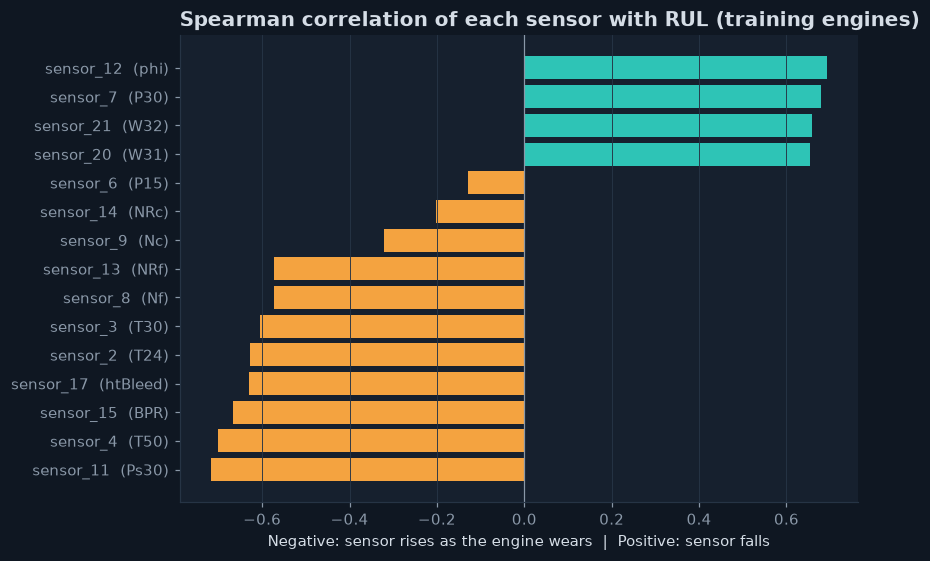

,sensor_11,sensor_4,sensor_15,sensor_17,sensor_2,sensor_3,sensor_8,sensor_13,sensor_9,sensor_14,sensor_6,sensor_20,sensor_21,sensor_7,sensor_12
spearman_with_rul,-0.718,-0.702,-0.666,-0.629,-0.629,-0.606,-0.574,-0.573,-0.322,-0.202,-0.128,0.653,0.657,0.679,0.693


In [ ]:
varying_sensors = [c for c in SENSOR_COLUMNS if c not in constant_sensors]
rul_correlation = (
    train_labelled[varying_sensors]
    .corrwith(train_labelled["rul"], method="spearman")
    .sort_values()
)

labels = [f"{name}  ({SENSOR_INFO[name][0]})" for name in rul_correlation.index]
colors = [theme.AMBER if value < 0 else theme.TEAL for value in rul_correlation]

fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(labels, rul_correlation, color=colors)
ax.axvline(0, color=theme.MUTED, linewidth=0.8)
ax.set_title("Spearman correlation of each sensor with RUL (training engines)")
ax.set_xlabel("Negative: sensor rises as the engine wears  |  Positive: sensor falls")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

rul_correlation.round(3).to_frame("spearman_with_rul").T

**Findings.**

- Twelve sensors have a clear relationship with RUL (absolute correlation above about 0.57). Sensor 11 (Ps30) and sensor 4 (T50) are the strongest; both rise as the engine wears.
- Four sensors fall as the engine wears: 7 (P30), 12 (phi), 20 and 21 (the turbine coolant bleeds).
- Sensors 9 and 14 (the core speeds) are weaker here, and sensor 6 is near zero, as expected from a two-value column.
- These values are diluted by the long healthy period, where sensors do not move at all. The relationship near the end of life is stronger than a whole-life correlation suggests. This is a first ranking, not a feature-selection decision.

## 9. Conclusions

| Question | Answer for FD001 |
|---|---|
| Shape | Train 20,631 × 26, test 13,096 × 26, 100 RUL labels |
| Engines | 100 train, 100 test |
| Data quality | No missing values, no duplicates, unbroken cycles |
| Engine life | 128 to 362 cycles, median 199 |
| Operating conditions | One (sea level) |
| Uninformative columns | `setting_3`; sensors 1, 5, 10, 16, 18, 19 constant; sensor 6 effectively constant |
| Informative sensors | 14 vary; 12 trend clearly with RUL |
| Training label | RUL = last cycle − current cycle (training engines only) |
| Degradation shape | Flat early, accelerating late |

**Limitations.** The data is simulated, noise was added artificially, and there is a single fault mode and flight condition. Conclusions drawn here apply to FD001 and must be re-checked on the other subsets.

## 10. Next steps

1. **Notebook 02 — Exploratory data analysis:** sensor trends across the whole fleet, healthy versus degraded behaviour, and a 3D view of the degradation path.
2. **Notebook 03 — Statistical analysis:** distributions, correlation between sensors (several look redundant, for example the two fan speeds), and tests of when degradation becomes detectable.
3. Carry three questions into Phase 4: which columns to drop, whether to cap RUL and at what value, and how to handle test engines with only ~30 cycles of history.